LAB 7 - CDS 230
Dae yeong Mun, Dong hyun Park

In [ ]:
# SVM Step 1 - Load and Explore Diabetes Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load dataset
diabetes_df = pd.read_csv("diabetes.csv")

print("Dataset shape:", diabetes_df.shape)
print("\nFirst 5 rows:")
print(diabetes_df.head())

print("\nDataset information:")
diabetes_df.info()

print("\nMissing values:")
print(diabetes_df.isnull().sum())

print("\nTarget distribution:")
print(diabetes_df["Outcome"].value_counts())

Dataset shape: (768, 9)

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies            

In [ ]:
# SVM Step 2 - Check Zero Values

zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

print("Zero values in each column:")
print((diabetes_df[zero_columns] == 0).sum())

Zero values in each column:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [ ]:
# SVM Step 3 - Data Preprocessing and Train/Test Split

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
import numpy as np

# Copy original dataset
df_clean = diabetes_df.copy()

# Replace invalid zeros with NaN
df_clean[zero_columns] = df_clean[zero_columns].replace(0, np.nan)

# Separate features and target
X = df_clean.drop('Outcome', axis=1)
y = df_clean['Outcome']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fill missing values using training median
imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

print("Training data shape:", X_train_imputed.shape)
print("Testing data shape:", X_test_imputed.shape)

print("\nMissing values after imputation:")
print("Training:", np.isnan(X_train_imputed).sum())
print("Testing:", np.isnan(X_test_imputed).sum())

Training data shape: (614, 8)
Testing data shape: (154, 8)

Missing values after imputation:
Training: 0
Testing: 0


In [ ]:
# SVM Step 4 - Standardize Features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train_imputed)

# Apply the same scaler to testing data
X_test_scaled = scaler.transform(X_test_imputed)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nTraining mean:")
print(X_train_scaled.mean(axis=0).round(2))

print("\nTraining standard deviation:")
print(X_train_scaled.std(axis=0).round(2))

Training data shape: (614, 8)
Testing data shape: (154, 8)

Training mean:
[-0. -0.  0. -0. -0.  0. -0. -0.]

Training standard deviation:
[1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
# SVM Step 5 - Train SVM Model and Make Predictions

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Create SVM model
svm_model = SVC(kernel='rbf', random_state=42)

# Train model
svm_model.fit(X_train_scaled, y_train)

# Predict testing data
y_pred = svm_model.predict(X_test_scaled)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("SVM Model: RBF Kernel")
print("Training samples:", len(X_train_scaled))
print("Testing samples:", len(X_test_scaled))
print("Accuracy:", round(accuracy, 4))
print("Accuracy (%):", round(accuracy * 100, 2), "%")

SVM Model: RBF Kernel
Training samples: 614
Testing samples: 154
Accuracy: 0.7403
Accuracy (%): 74.03 %


SVM Model Evaluation
Accuracy: 0.7403
Precision: 0.6522
Recall: 0.5556
F1-score: 0.6

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.84      0.81       100
           1       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154



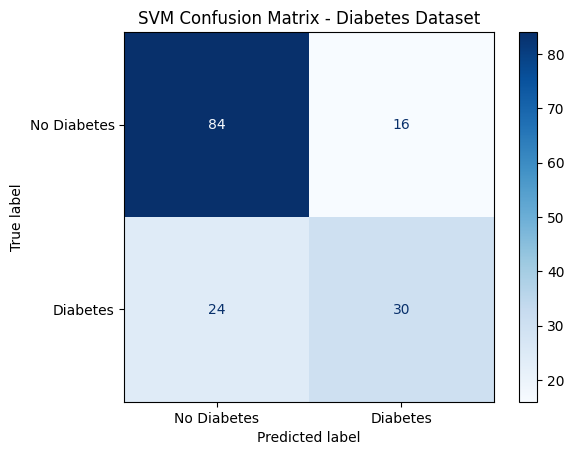

In [ ]:
# SVM Step 6 - Model Evaluation

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate evaluation metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("SVM Model Evaluation")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot(cmap="Blues")
plt.title("SVM Confusion Matrix - Diabetes Dataset")
plt.show()

### SVM Results and Interpretation – Diabetes Dataset

In this analysis, we used the Pima Indians Diabetes dataset, which contains 768 samples and 8 numerical features. The goal was to predict whether a person has diabetes based on health-related information.

First, we checked the dataset and replaced invalid zero values with missing values. We divided the data into 80% training and 20% testing. Missing values were filled using the median values from the training data, and the features were standardized using StandardScaler.

We then trained a Support Vector Machine (SVM) model using the RBF kernel. The model achieved an accuracy of 74.03% on the test data.

For the diabetes-positive class, the precision was 65.22%, recall was 55.56%, and F1-score was 60.00%. The confusion matrix showed that the model correctly classified 84 people without diabetes and 30 people with diabetes. However, it incorrectly classified 16 people as having diabetes and missed 24 people who were actually diabetes-positive in the dataset.

Overall, SVM was able to identify some patterns in the health data, but its performance was limited. In particular, the model missed many diabetes-positive cases. This shows that accuracy alone is not enough to evaluate a classification model, especially when identifying positive cases is important.

Dataset link: https://www.kaggle.com/code/umairziact/diabetes-dataset